# Bank Marketing: Predicting Term-Deposit Subscription

**Dataset:** Bank Marketing (UCI Machine Learning Repository, Moro et al., 2014)
**File used:** bank-additional-full.csv

### Why I chose this file
The UCI page has four files. I use bank-additional-full.csv because:
- it has all 41,188 examples (the 10% files are only for slow algorithms),
- it is the version that is very close to the data in the original paper.



## 0. Setup and data loading
First I import all libraries. I also fix RANDOM_STATE = 42, so the results are the same every time I run the notebook.

In [ ]:
# Data: put bank-additional-full.csv into the data/ folder (see data/README.md)
DATA_PATH = "data/bank-additional-full.csv"

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils import resample

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [ ]:
df = pd.read_csv(DATA_PATH, sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Exploratory Data Analysis (EDA)

### 1.1 Dataset description
I check the size of the data, the type of each column and the basic statistics.

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1], "(20 features + 1 target)")
print()
df.info()

Rows: 41188
Columns: 21 (20 features + 1 target)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-

In [ ]:
num_cols_all = df.select_dtypes(include="number").columns.tolist()
cat_cols_all = [c for c in df.columns if c not in num_cols_all and c != "y"]
print("Numerical features (%d):" % len(num_cols_all), num_cols_all)
print("Categorical features (%d):" % len(cat_cols_all), cat_cols_all)
print("Target: y")

Numerical features (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Target: y


In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


**Interpretation.**
The dataset has 41,188 rows and 21 columns: 20 features and the target y.
- **10 numerical features:** client age, information about the last call (duration), about the campaign (campaign, pdays, previous) and 5 economic indicators (emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed).
- **10 categorical features:** job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome.
- **Target:** y - did the client subscribe to a term deposit (yes/no).

From describe() I see some interesting things:
- pdays has median 999. In this dataset 999 is not a real number of days, it means "the client was not contacted before".
- campaign (number of calls in this campaign) has mean 2.57 but max 56, so there are outliers.
- duration (call length in seconds) also has a very long tail (max 4,918 s).

### 1.2 Missing values, "unknown" values and duplicates
In this dataset missing values are not NaN, they are written as the word "unknown". So I count both.

In [ ]:
print("NaN values in the whole table:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print()

unknown = (df[cat_cols_all] == "unknown").sum()
unknown = unknown[unknown > 0].sort_values(ascending=False)
unknown_pct = (unknown / len(df) * 100).round(2)
pd.DataFrame({"unknown_count": unknown, "unknown_%": unknown_pct})

NaN values in the whole table: 0
Duplicated rows: 12



,unknown_count,unknown_%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


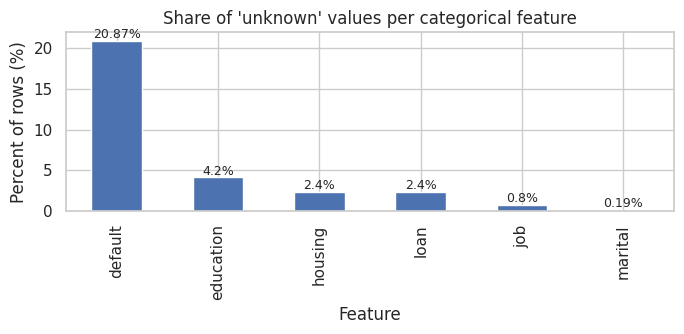

Figure 1. 'unknown' is the hidden missing value in this dataset. Most of them are in the 'default' column.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
unknown_pct.plot(kind="bar", color="#4C72B0", ax=ax)
ax.set_title("Share of 'unknown' values per categorical feature")
ax.set_xlabel("Feature")
ax.set_ylabel("Percent of rows (%)")
for i, v in enumerate(unknown_pct):
    ax.text(i, v + 0.3, f"{v}%", ha="center", fontsize=9)
plt.tight_layout()
plt.show()
print("Figure 1. 'unknown' is the hidden missing value in this dataset. "
      "Most of them are in the 'default' column.")

**Interpretation.**
- There are **no NaN values**, but there are many "unknown" values. The biggest problem is default (20.9% unknown), then education (4.2%), housing and loan (2.4% each). job and marital have less than 1%.
- There are **12 duplicated rows**. I will remove them in preprocessing.
- Also, default has only **3 "yes"** values in the whole data, so almost all clients are "no" or "unknown".

### 1.3 Target variable - class distribution (imbalance check)

     count  percent
y                  
no   36548    88.73
yes   4640    11.27

Imbalance ratio (no : yes) = 7.9 : 1


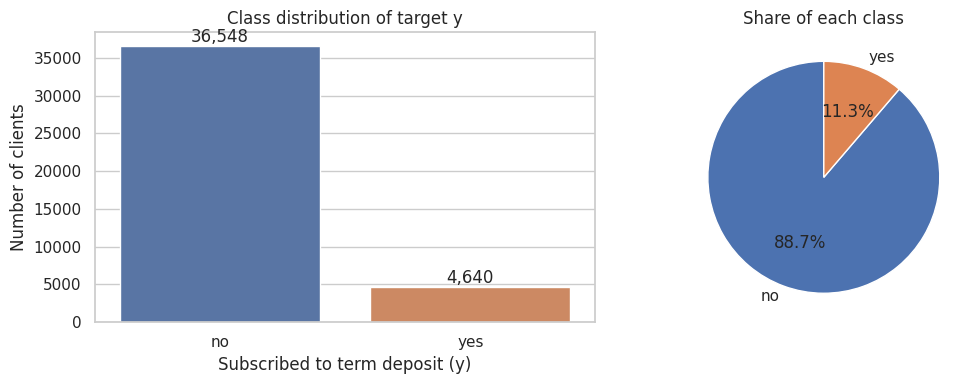

Figure 2. Only about 11% of clients said 'yes'. The dataset is strongly imbalanced.


In [ ]:
counts = df["y"].value_counts()
percent = df["y"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))
print("\nImbalance ratio (no : yes) = %.1f : 1" % (counts["no"] / counts["yes"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="y", data=df, order=["no", "yes"],
              palette=["#4C72B0", "#DD8452"], ax=axes[0])
axes[0].set_title("Class distribution of target y")
axes[0].set_xlabel("Subscribed to term deposit (y)")
axes[0].set_ylabel("Number of clients")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

axes[1].pie(counts, labels=["no", "yes"], autopct="%1.1f%%",
            colors=["#4C72B0", "#DD8452"], startangle=90)
axes[1].set_title("Share of each class")
plt.tight_layout()
plt.show()
print("Figure 2. Only about 11% of clients said 'yes'. The dataset is strongly imbalanced.")

**Interpretation.**
The data is **imbalanced**: 36,548 clients said "no" (88.7%) and only 4,640 said "yes" (11.3%). The ratio is about **7.9 : 1**.

This is important for the next steps:
- **Accuracy is a bad metric here.** A "model" that always says "no" gets 88.7% accuracy but is useless.
- So I will use **ROC-AUC, PR-AUC, F1, Precision and Recall**, as the task says.
- I will use a **stratified** train/test split and **class weights** to help the models see the small "yes" class.

### 1.4 Numerical features vs target
I compare the distributions of the most important numerical features for "yes" and "no" clients.

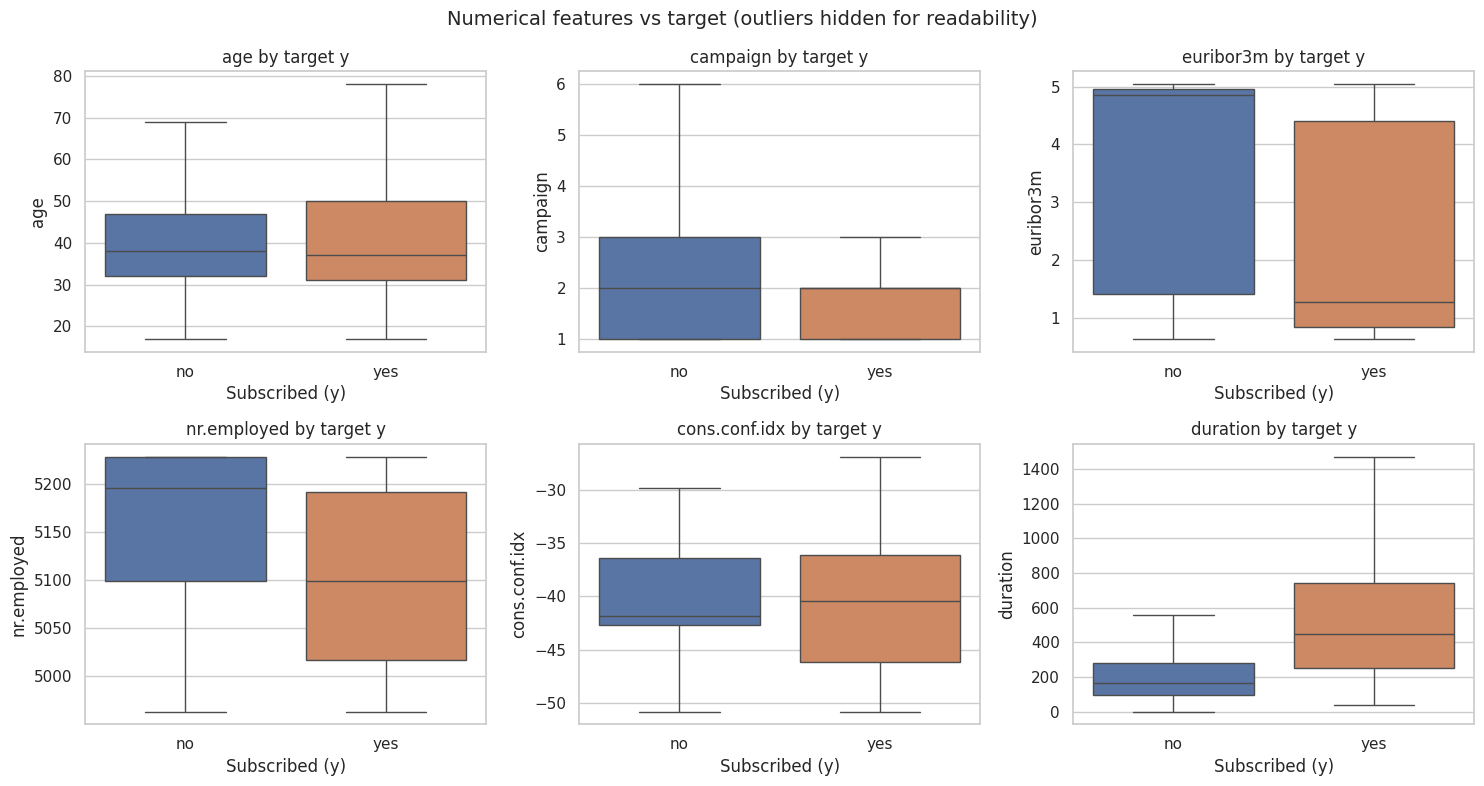

Figure 3. Economic features (euribor3m, nr.employed) and duration look very different for 'yes' and 'no' clients. Age and campaign are less different.


In [ ]:
plot_num = ["age", "campaign", "euribor3m", "nr.employed", "cons.conf.idx", "duration"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), plot_num):
    sns.boxplot(x="y", y=col, data=df, order=["no", "yes"],
                palette=["#4C72B0", "#DD8452"], ax=ax, showfliers=False)
    ax.set_title(f"{col} by target y")
    ax.set_xlabel("Subscribed (y)")
    ax.set_ylabel(col)
plt.suptitle("Numerical features vs target (outliers hidden for readability)", fontsize=14)
plt.tight_layout()
plt.show()
print("Figure 3. Economic features (euribor3m, nr.employed) and duration look very different "
      "for 'yes' and 'no' clients. Age and campaign are less different.")

In [ ]:
# Mean values per class - a table to support the plots
df.groupby("y")[plot_num + ["pdays", "previous"]].mean().round(2).T

y,no,yes
age,39.91,40.91
campaign,2.63,2.05
euribor3m,3.81,2.12
nr.employed,5176.17,5095.12
cons.conf.idx,-40.59,-39.79
duration,220.84,553.19
pdays,984.11,792.04
previous,0.13,0.49


**Interpretation.**
- **euribor3m and nr.employed**: "yes" clients were mostly called when the interest rate (euribor) and number of employees were low. So the economic situation is very important.
- **duration**: "yes" calls are much longer (mean 553 s vs 221 s). But there is a problem - the duration is known only after the call ends, and if duration = 0 then y is always "no". The dataset authors say this feature should be removed for a realistic model. So I will drop duration to avoid data leakage.
- **campaign**: "yes" clients were called a bit fewer times. Many calls in one campaign do not help.
- **age**: the medians are almost the same, but the "yes" group has more very young and old people (see next plot).
- **previous**: "yes" clients were contacted more often in older campaigns.

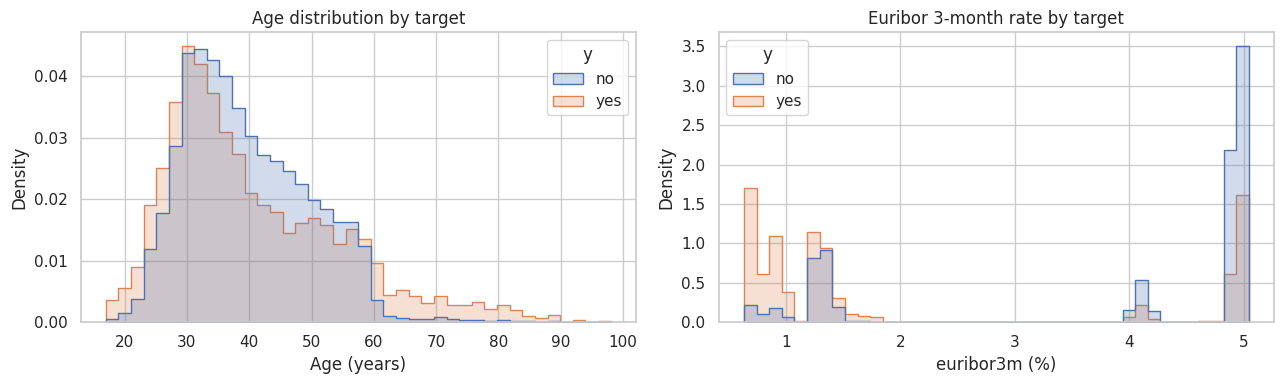

Figure 4. Clients older than ~60 and younger than ~25 say 'yes' more often. Most 'yes' answers happen when euribor3m is low (below ~2%).


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="age", hue="y", hue_order=["no", "yes"], stat="density",
             common_norm=False, bins=40, element="step", ax=axes[0])
axes[0].set_title("Age distribution by target")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Density")

sns.histplot(data=df, x="euribor3m", hue="y", hue_order=["no", "yes"], stat="density",
             common_norm=False, bins=40, element="step", ax=axes[1])
axes[1].set_title("Euribor 3-month rate by target")
axes[1].set_xlabel("euribor3m (%)")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.show()
print("Figure 4. Clients older than ~60 and younger than ~25 say 'yes' more often. "
      "Most 'yes' answers happen when euribor3m is low (below ~2%).")

### 1.5 Categorical features vs target
For categorical features, the best way to compare is the **subscription rate** (% of "yes") inside each category.

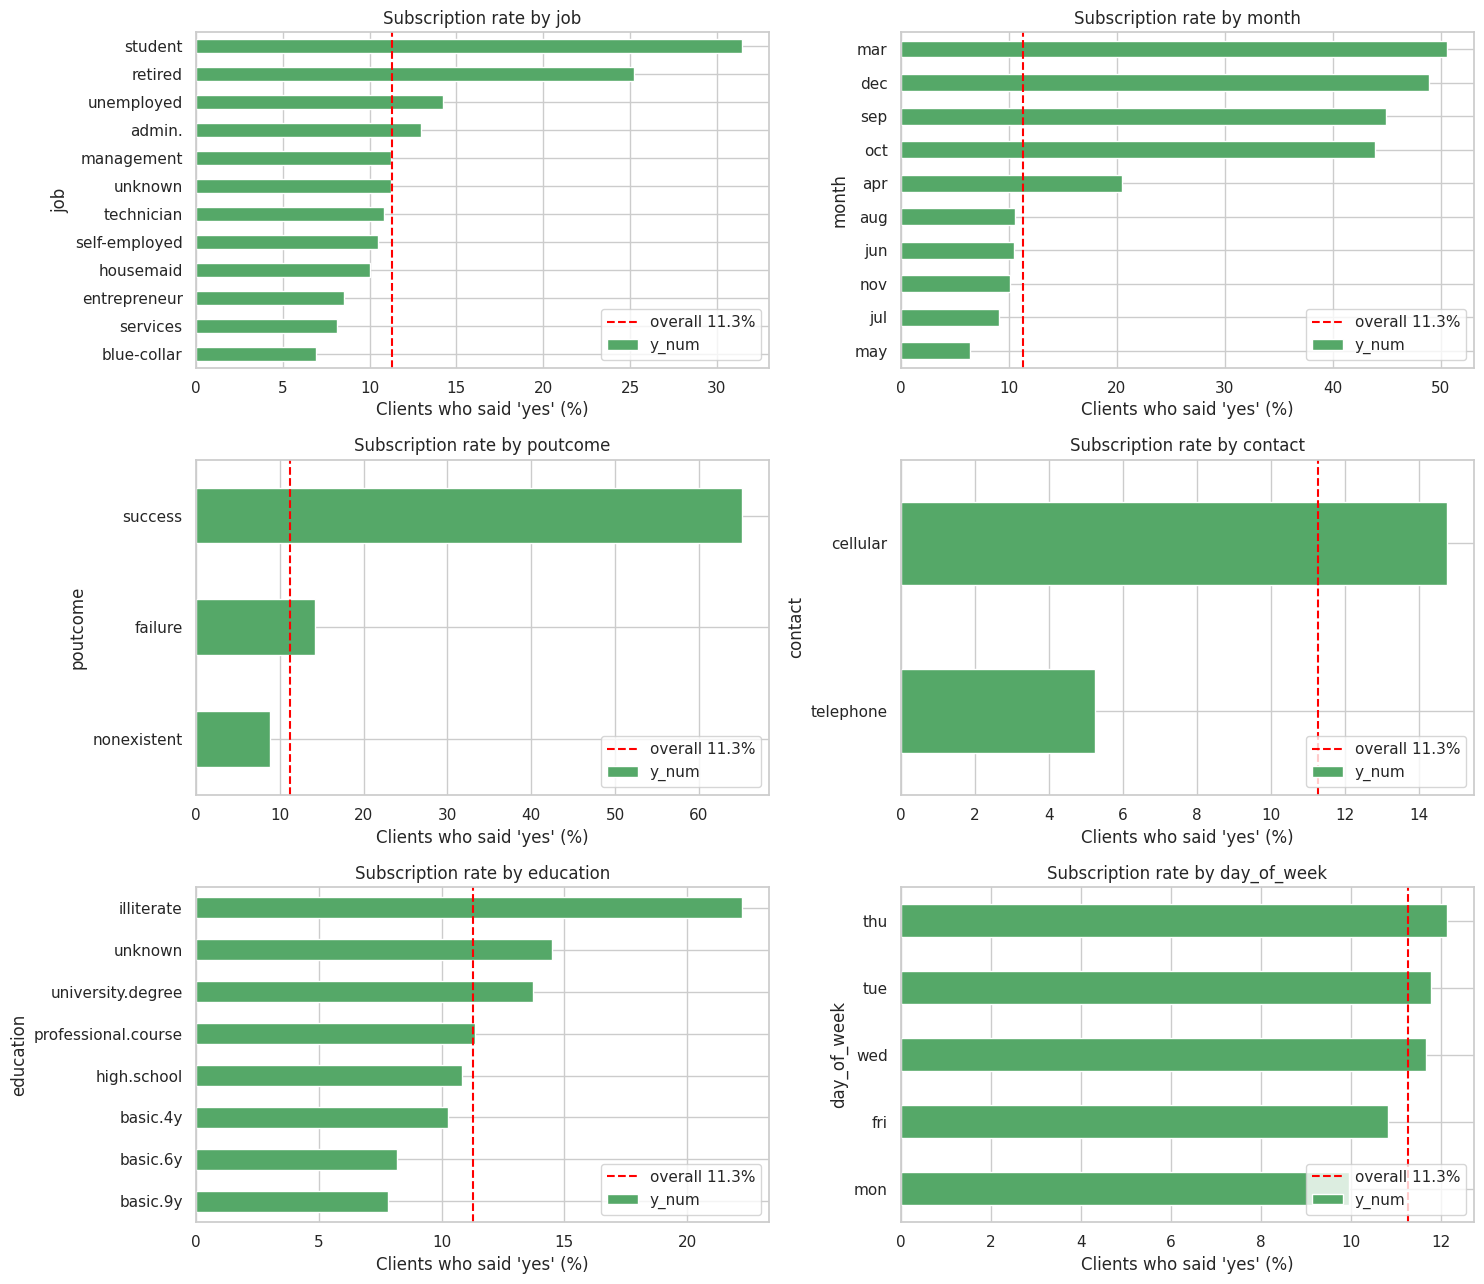

Figure 5. Subscription rate per category. The red line is the average rate (11.3%). poutcome, month and contact show the biggest differences.


In [ ]:
df["y_num"] = (df["y"] == "yes").astype(int)
overall_rate = df["y_num"].mean() * 100

plot_cat = ["job", "month", "poutcome", "contact", "education", "day_of_week"]
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, col in zip(axes.ravel(), plot_cat):
    rate = (df.groupby(col)["y_num"].mean() * 100).sort_values()
    rate.plot(kind="barh", color="#55A868", ax=ax)
    ax.axvline(overall_rate, color="red", linestyle="--", label=f"overall {overall_rate:.1f}%")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("Clients who said 'yes' (%)")
    ax.set_ylabel(col)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print("Figure 5. Subscription rate per category. The red line is the average rate (11.3%). "
      "poutcome, month and contact show the biggest differences.")

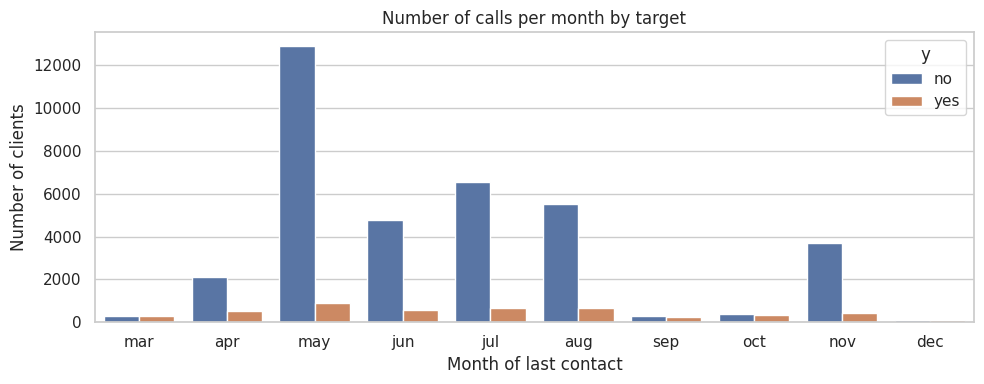

Figure 6. May has the most calls but a low success rate. March, September, October and December have few calls but a very high success rate.


In [ ]:
# Number of calls per month - to understand the month effect
fig, ax = plt.subplots(figsize=(10, 4))
order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
sns.countplot(x="month", hue="y", data=df, order=order, hue_order=["no", "yes"],
              palette=["#4C72B0", "#DD8452"], ax=ax)
ax.set_title("Number of calls per month by target")
ax.set_xlabel("Month of last contact")
ax.set_ylabel("Number of clients")
plt.tight_layout()
plt.show()
print("Figure 6. May has the most calls but a low success rate. "
      "March, September, October and December have few calls but a very high success rate.")

**Interpretation.**
- **poutcome** is the strongest categorical feature: if the previous campaign was a **success**, 65.1% of clients say "yes" again. For new clients ("nonexistent") it is only 8.8%.
- **month**: May has the most calls but the lowest rate (6.4%). In March, September, October and December the rate is 44–51%, but there were only a few calls in these months.
- **contact**: calls to a **cellular** phone are about 3 times more successful (14.7%) than to a home **telephone** (5.2%).
- **job**: **students** (31.4%) and **retired** people (25.2%) say "yes" most often; **blue-collar** workers (6.9%) the least. This agrees with the age plot.
- **education**: small differences. The "illiterate" group is very small, so its rate is not reliable.
- **day_of_week**: almost no difference, so it is probably a weak feature.

### 1.6 Correlation heatmap
I compute Pearson correlation between all numerical features and the target (encoded as 0/1).

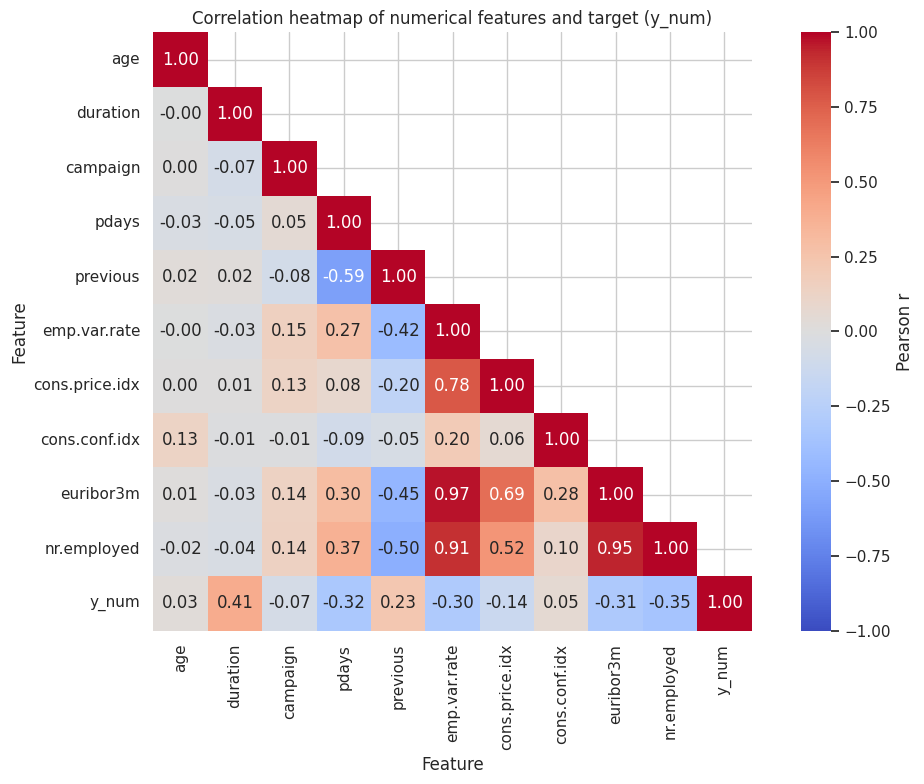

Figure 7. emp.var.rate, euribor3m and nr.employed are almost the same information (r > 0.9).


In [ ]:
corr = df[num_cols_all + ["y_num"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation heatmap of numerical features and target (y_num)")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()
print("Figure 7. emp.var.rate, euribor3m and nr.employed are almost the same information (r > 0.9).")

In [ ]:
print("Correlation with target y (sorted):")
print(corr["y_num"].drop("y_num").sort_values(ascending=False).round(3))

Correlation with target y (sorted):
duration          0.405
previous          0.230
cons.conf.idx     0.055
age               0.030
campaign         -0.066
cons.price.idx   -0.136
emp.var.rate     -0.298
euribor3m        -0.308
pdays            -0.325
nr.employed      -0.355
Name: y_num, dtype: float64


**Interpretation.**
- **Correlation with target:** the strongest is duration (+0.41), but I will drop it (leakage). After that: nr.employed (−0.35), pdays (−0.32), euribor3m (−0.31), emp.var.rate (−0.30) and previous (+0.23). Negative values mean: when the economy indicator is lower, more people subscribe.
- **Multicollinearity:** emp.var.rate, euribor3m and nr.employed are very strongly correlated with each other (0.91–0.97). They carry almost the same information. This is bad for Logistic Regression (unstable coefficients), so in preprocessing I keep only **nr.employed** (the one most correlated with y) and drop the other two.
- pdays and previous are also correlated (−0.59), because both describe the previous campaign.

In [ ]:
df = df.drop(columns="y_num")   # helper column only for EDA

## 2. Data Preprocessing
In this part I use these tools from the lectures:

| Step | Tool | Why |
|---|---|---|
| 2.1 | Remove duplicates | duplicates can give the same row in train and test |
| 2.2 | Remove leakage feature (duration) | it is not known before the call |
| 2.3 | Handle special values (pdays = 999) + feature engineering | 999 is a code, not a number |
| 2.4 | Handle missing values (unknown): mode imputation / keep as category | |
| 2.5 | Remove multicollinear features | emp.var.rate, euribor3m duplicate nr.employed |
| 2.6 | Label encoding of target | models need 0/1 |
| 2.7 | Stratified train/test split | keep the same class ratio in both parts |
| 2.8 | Outlier treatment (IQR + capping) | campaign has extreme values |
| 2.9 | One-Hot Encoding + Standard Scaling (ColumnTransformer + Pipeline) | categorical → numbers, same scale for KNN/SVM/LR |
| 2.10 | Class imbalance: class weights / oversampling | the "yes" class is only 11% |

### 2.1 Remove duplicates

In [ ]:
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After: ", df.shape)

Before: (41188, 21)
After:  (41176, 21)


### 2.2 Remove the leakage feature duration
The duration of the call is known only **after** the call. A real bank wants to predict the result **before** calling, so this feature is not fair to use. With it, the models would look much better than they really are.

In [ ]:
df = df.drop(columns="duration")
print("Columns now:", df.shape[1])

Columns now: 20


### 2.3 Special value pdays = 999 and feature engineering
pdays = number of days since the client was contacted in a previous campaign. 999 means "never contacted". If I leave 999, the model thinks it is a very big number of days. So:
1. I create a new binary feature prev_contacted (1 = was contacted before, 0 = not).
2. I replace 999 by -1, so the real values (0-27 days) are not mixed with a fake big number.

In [ ]:
print("Share of pdays == 999: %.1f%%" % ((df["pdays"] == 999).mean() * 100))
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays"] = df["pdays"].replace(999, -1)

print(df.groupby("prev_contacted")["y"].apply(lambda s: (s == "yes").mean() * 100).round(1)
        .rename("subscription rate %"))

Share of pdays == 999: 96.3%
prev_contacted
0     9.3
1    63.8
Name: subscription rate %, dtype: float64


**Interpretation.** 96.3% of clients were never contacted before. But the clients who **were** contacted before subscribe much more often (63.8% vs 9.3%). So the new feature prev_contacted is useful and easy for the models to understand.

### 2.4 Handle "unknown" values
I use two different strategies, because the amount of "unknown" is different:
- **job and marital** - less than 1% unknown -> I replace "unknown" with the **most frequent value (mode)**. This is simple imputation.
- **education, default, housing, loan** - more unknowns. Here "unknown" can carry information (for example, a client who does not want to say if they have credit in default). So I **keep "unknown" as a separate category**. One-Hot Encoding will make its own column for it.

In [ ]:
for col in ["job", "marital"]:
    df[col] = df[col].replace("unknown", np.nan)

imputer = SimpleImputer(strategy="most_frequent")
df[["job", "marital"]] = imputer.fit_transform(df[["job", "marital"]])

print("Mode used:", dict(zip(["job", "marital"], imputer.statistics_)))
print("'unknown' left in job/marital:", (df[["job", "marital"]] == "unknown").sum().sum())
print("Rate of 'yes' for default == unknown: %.1f%%" %
      ((df.loc[df["default"] == "unknown", "y"] == "yes").mean() * 100))
print("Rate of 'yes' for default == no:      %.1f%%" %
      ((df.loc[df["default"] == "no", "y"] == "yes").mean() * 100))

Mode used: {'job': 'admin.', 'marital': 'married'}
'unknown' left in job/marital: 0
Rate of 'yes' for default == unknown: 5.2%
Rate of 'yes' for default == no:      12.9%


**Interpretation.** job and marital are now clean. For default we can see that "unknown" clients subscribe less often (5.2%) than "no" clients (12.9%), so "unknown" really is useful information - this confirms the choice to keep it as a category.

### 2.5 Remove multicollinear features
From the heatmap: emp.var.rate-euribor3m r = 0.97, euribor3m-nr.employed r = 0.95. I keep nr.employed (strongest link with y) and drop the other two.

In [ ]:
df = df.drop(columns=["emp.var.rate", "euribor3m"])
print("Remaining economic features:", ["cons.price.idx", "cons.conf.idx", "nr.employed"])
print("Shape:", df.shape)

Remaining economic features: ['cons.price.idx', 'cons.conf.idx', 'nr.employed']
Shape: (41176, 19)


### 2.6 Encode the target and 2.7 Stratified train/test split

In [ ]:
le = LabelEncoder()
y = le.fit_transform(df["y"])          # no -> 0, yes -> 1
X = df.drop(columns="y")
print("Classes:", {c: int(v) for c, v in zip(le.classes_, le.transform(le.classes_))})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Share of 'yes' in train: %.2f%%, in test: %.2f%%" %
      (y_train.mean() * 100, y_test.mean() * 100))

Classes: {'no': 0, 'yes': 1}
Train: (32940, 18)  Test: (8236, 18)
Share of 'yes' in train: 11.27%, in test: 11.27%


**Interpretation.** I use 80% for training and 20% for testing. Because of stratify=y, both parts have the same share of "yes" (11.3%). The test set is not used for any fitting (scaling, capping, tuning) - only for the final evaluation. This avoids data leakage.

### 2.8 Outliers: IQR detection and capping
I check outliers with the IQR rule (value > Q3 + 1.5·IQR). I compute the limits **on the training set only** and then apply them to train and test.

In [ ]:
def iqr_upper(series):
    q1, q3 = series.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

for col in ["age", "campaign", "previous"]:
    up = iqr_upper(X_train[col])
    n_out = (X_train[col] > up).sum()
    print(f"{col:10s} upper IQR limit = {up:6.1f}   outliers in train = {n_out} ({n_out/len(X_train)*100:.1f}%)")

age        upper IQR limit =   69.5   outliers in train = 383 (1.2%)
campaign   upper IQR limit =    6.0   outliers in train = 1911 (5.8%)
previous   upper IQR limit =    0.0   outliers in train = 4509 (13.7%)


Cap for campaign (99th percentile of train): 14.0


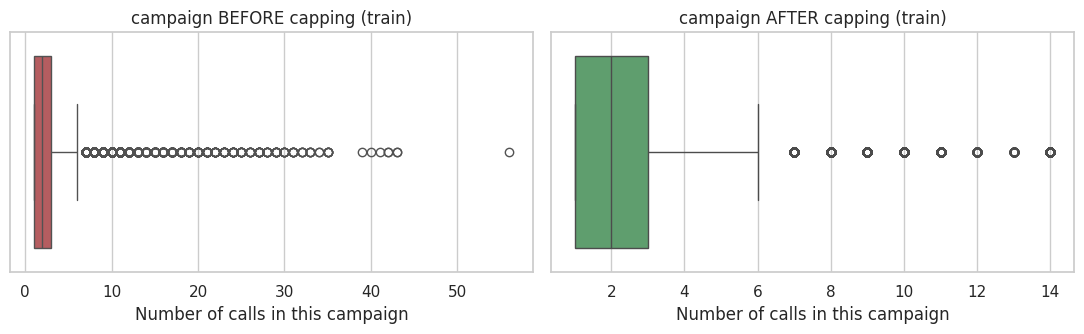

Figure 8. Capping removes the extreme values of campaign but keeps all rows.


In [ ]:
# 'campaign' has extreme values (up to 56 calls). I cap it at the 99th percentile of the train set.
cap = X_train["campaign"].quantile(0.99)
print("Cap for campaign (99th percentile of train):", cap)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=X_train["campaign"], ax=axes[0], color="#C44E52")
axes[0].set_title("campaign BEFORE capping (train)")
axes[0].set_xlabel("Number of calls in this campaign")

X_train["campaign"] = X_train["campaign"].clip(upper=cap)
X_test["campaign"] = X_test["campaign"].clip(upper=cap)

sns.boxplot(x=X_train["campaign"], ax=axes[1], color="#55A868")
axes[1].set_title("campaign AFTER capping (train)")
axes[1].set_xlabel("Number of calls in this campaign")
plt.tight_layout()
plt.show()
print("Figure 8. Capping removes the extreme values of campaign but keeps all rows.")

**Interpretation.**
- age: the IQR rule marks old clients as outliers, but they are **real people** and they are important (retired people subscribe often). So I **do not change** age.
- previous: almost all values are 0, so the IQR rule marks every non-zero value as an outlier. These values are real and useful, so I keep them.
- campaign: values like 40–56 calls are very rare and can hurt Logistic Regression, KNN and SVM. I **cap** them at the 99th percentile instead of deleting rows, so no data is lost.

### 2.9 Encoding and scaling with ColumnTransformer + Pipeline
- **One-Hot Encoding** for all categorical features (they have no natural order, except education, but One-Hot is safe for it too). handle_unknown="ignore" protects from new categories in test.
- **StandardScaler** for numerical features (mean 0, std 1). This is necessary for distance-based models (KNN, SVM) and for Logistic Regression. Trees do not need scaling, but it does not hurt them.
- Everything is put inside a Pipeline, so the scaler and encoder are **fitted only on training data** (also inside each cross-validation fold).

In [ ]:
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numerical (%d):" % len(num_features), num_features)
print("Categorical (%d):" % len(cat_features), cat_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])


X_train_prep = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()
print("\nNumber of features after One-Hot Encoding:", X_train_prep.shape[1])

Numerical (8): ['age', 'campaign', 'pdays', 'previous', 'cons.price.idx', 'cons.conf.idx', 'nr.employed', 'prev_contacted']
Categorical (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of features after One-Hot Encoding: 59


### 2.10 Class imbalance
I use two techniques:
1. **Class weights** (class_weight="balanced", and scale_pos_weight for XGBoost). The model gets a bigger penalty for mistakes on the small "yes" class. Nothing is added or deleted from the data.
2. **Random oversampling** of the minority class (only in the training set). I test it with Logistic Regression to compare with class weights.

KNN has no class weights, so for KNN I use the predicted probability and the PR curve to judge it.

In [ ]:
neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos
print("Train: no = %d, yes = %d, scale_pos_weight = %.2f" % (neg, pos, scale_pos_weight))

# Random oversampling (train only) - simple version of the idea behind SMOTE
train_df = X_train.copy()
train_df["target"] = y_train
majority = train_df[train_df["target"] == 0]
minority = train_df[train_df["target"] == 1]
minority_up = resample(minority, replace=True, n_samples=len(majority), random_state=RANDOM_STATE)
train_over = pd.concat([majority, minority_up]).sample(frac=1, random_state=RANDOM_STATE)
X_train_over, y_train_over = train_over.drop(columns="target"), train_over["target"].values
print("After oversampling:", np.bincount(y_train_over))

Train: no = 29229, yes = 3711, scale_pos_weight = 7.88
After oversampling: [29229 29229]


In [ ]:
# Compare: no balancing vs class weights vs oversampling (Logistic Regression, test set)
def quick_lr(Xtr, ytr, cw=None):
    m = Pipeline([("prep", preprocessor), ("clf", LogisticRegression(max_iter=2000, class_weight=cw))])
    m.fit(Xtr, ytr)
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {"ROC-AUC": roc_auc_score(y_test, p), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)}

balance_cmp = pd.DataFrame({
    "No balancing": quick_lr(X_train, y_train),
    "Class weights": quick_lr(X_train, y_train, cw="balanced"),
    "Oversampling": quick_lr(X_train_over, y_train_over),
}).T.round(3)
balance_cmp

,ROC-AUC,Precision,Recall,F1
No balancing,0.796,0.656,0.216,0.324
Class weights,0.799,0.351,0.642,0.454
Oversampling,0.798,0.352,0.649,0.457


**Interpretation.**
- **Without balancing**, Logistic Regression is very "lazy": it predicts "no" almost always, so **Recall is only about 0.21** - it finds only 1 of 5 real subscribers.
- **Class weights** and **oversampling** give almost the same result: Recall goes up to 0.64, Precision goes down to 0.35, F1 becomes higher.
- **ROC-AUC does not change much** (0.79–0.80), because ROC-AUC does not depend on the threshold. Balancing mostly moves the decision threshold.

Both methods work. I choose **class weights** for the main models, because they do not create copies of rows (no risk of overfitting on copies, and training is faster).

## 3. Model training
I train 6 models. Each model is a Pipeline(preprocessor -> classifier).
- **Hyperparameter tuning:** for Decision Tree and KNN I use GridSearchCV with 5-fold stratified cross-validation and ROC-AUC as the score. For the other models I use reasonable parameters (to keep the run time short).
- **SVM** is slow on big data (training time grows faster than the number of rows). The UCI page also says this. So I train SVM on a stratified random sample of 10,000 training rows.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([("prep", preprocessor), ("clf", clf)])

models = {}

### 3.1 Logistic Regression (baseline)

In [ ]:
models["Logistic Regression"] = make_pipe(
    LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0))
models["Logistic Regression"].fit(X_train, y_train)
print("Done")

Done


### 3.2 Decision Tree (with GridSearchCV)

In [ ]:
dt_grid = GridSearchCV(
    make_pipe(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    param_grid={"clf__max_depth": [3, 5, 7, 10],
                "clf__min_samples_leaf": [20, 50, 100]},
    scoring="roc_auc", cv=cv, n_jobs=-1)
dt_grid.fit(X_train, y_train)
print("Best params:", dt_grid.best_params_)
print("Best CV ROC-AUC: %.4f" % dt_grid.best_score_)
models["Decision Tree"] = dt_grid.best_estimator_

Best params: {'clf__max_depth': 7, 'clf__min_samples_leaf': 100}
Best CV ROC-AUC: 0.7803


**Interpretation.** A tree without limits overfits (it memorizes the training data). Grid search chose **max_depth = 7** and **min_samples_leaf = 100** that make the tree simpler and more general.

### 3.3 Random Forest

In [ ]:
models["Random Forest"] = make_pipe(RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_leaf=10,
    class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
models["Random Forest"].fit(X_train, y_train)
print("Done")

Done


### 3.4 XGBoost (gradient boosting)

In [ ]:
models["XGBoost"] = make_pipe(XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,   # handles imbalance
    eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1))
models["XGBoost"].fit(X_train, y_train)
print("Done")

Done


### 3.5 KNN (with GridSearchCV)

In [ ]:
knn_grid = GridSearchCV(
    make_pipe(KNeighborsClassifier()),
    param_grid={"clf__n_neighbors": [15, 35, 75, 125],
                "clf__weights": ["uniform", "distance"]},
    scoring="roc_auc", cv=cv, n_jobs=-1)
knn_grid.fit(X_train, y_train)
print("Best params:", knn_grid.best_params_)
print("Best CV ROC-AUC: %.4f" % knn_grid.best_score_)
models["KNN"] = knn_grid.best_estimator_

Best params: {'clf__n_neighbors': 125, 'clf__weights': 'uniform'}
Best CV ROC-AUC: 0.7841


**Interpretation.** Small k (like 5) gives noisy probabilities on imbalanced data. Grid search chose a **large k = 125**, so each prediction is an average over many neighbours and the probabilities become smoother.

### 3.6 SVM (RBF kernel, trained on a 10,000-row stratified sample)

In [ ]:
X_svm, _, y_svm, _ = train_test_split(X_train, y_train, train_size=10000,
                                      stratify=y_train, random_state=RANDOM_STATE)
models["SVM"] = make_pipe(SVC(kernel="rbf", C=1.0, gamma="scale",
                              class_weight="balanced", random_state=RANDOM_STATE))
models["SVM"].fit(X_svm, y_svm)
print("SVM trained on", X_svm.shape[0], "rows, share of 'yes' = %.3f" % y_svm.mean())

SVM trained on 10000 rows, share of 'yes' = 0.113


## 4. Evaluation
For each model I compute on the **test set**:
- **ROC-AUC** - how well the model ranks "yes" clients above "no" clients (0.5 = random, 1 = perfect).
- **PR-AUC** (average precision) - better for imbalanced data; random level here is ≈0.113 (share of "yes").
- **Precision, Recall, F1** at the default threshold 0.5.
- **Confusion matrix.**

SVM gives a decision score instead of a probability, so for SVM I use decision_function for ROC/PR curves (the curves only need a ranking score).

In [ ]:
def get_scores(model, X):
    clf = model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

results, scores, preds = [], {}, {}
for name, model in models.items():
    s = get_scores(model, X_test)
    p = model.predict(X_test)
    scores[name], preds[name] = s, p
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, s),
        "PR-AUC": average_precision_score(y_test, s),
        "F1": f1_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "Accuracy": accuracy_score(y_test, p),
    })

results_df = (pd.DataFrame(results).set_index("Model")
              .sort_values("ROC-AUC", ascending=False).round(4))
results_df

,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
Model,,,,,,
Random Forest,0.8078,0.4771,0.5009,0.4160,0.6293,0.8587
Decision Tree,0.8018,0.4577,0.4902,0.4051,0.6207,0.8545
Logistic Regression,0.7986,0.4449,0.4537,0.3508,0.6422,0.8258
KNN,0.7950,0.4470,0.3231,0.6546,0.2144,0.8987
XGBoost,0.7875,0.4403,0.3881,0.2642,0.7306,0.7404
SVM,0.7761,0.3861,0.5046,0.4236,0.6239,0.8619


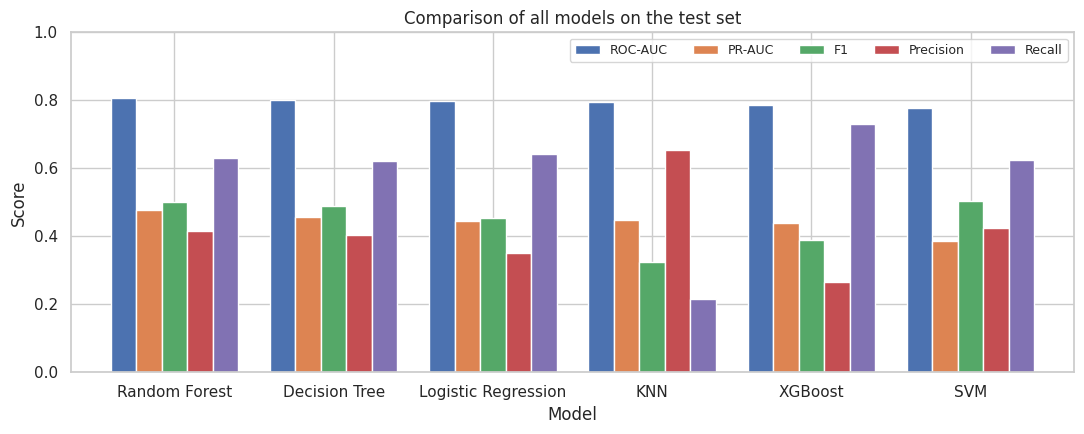

Figure 9. Metric comparison (threshold 0.5 for F1, Precision, Recall).


In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
results_df[["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]].plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Comparison of all models on the test set")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", ncol=5, fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Figure 9. Metric comparison (threshold 0.5 for F1, Precision, Recall).")

### 4.1 Confusion matrices

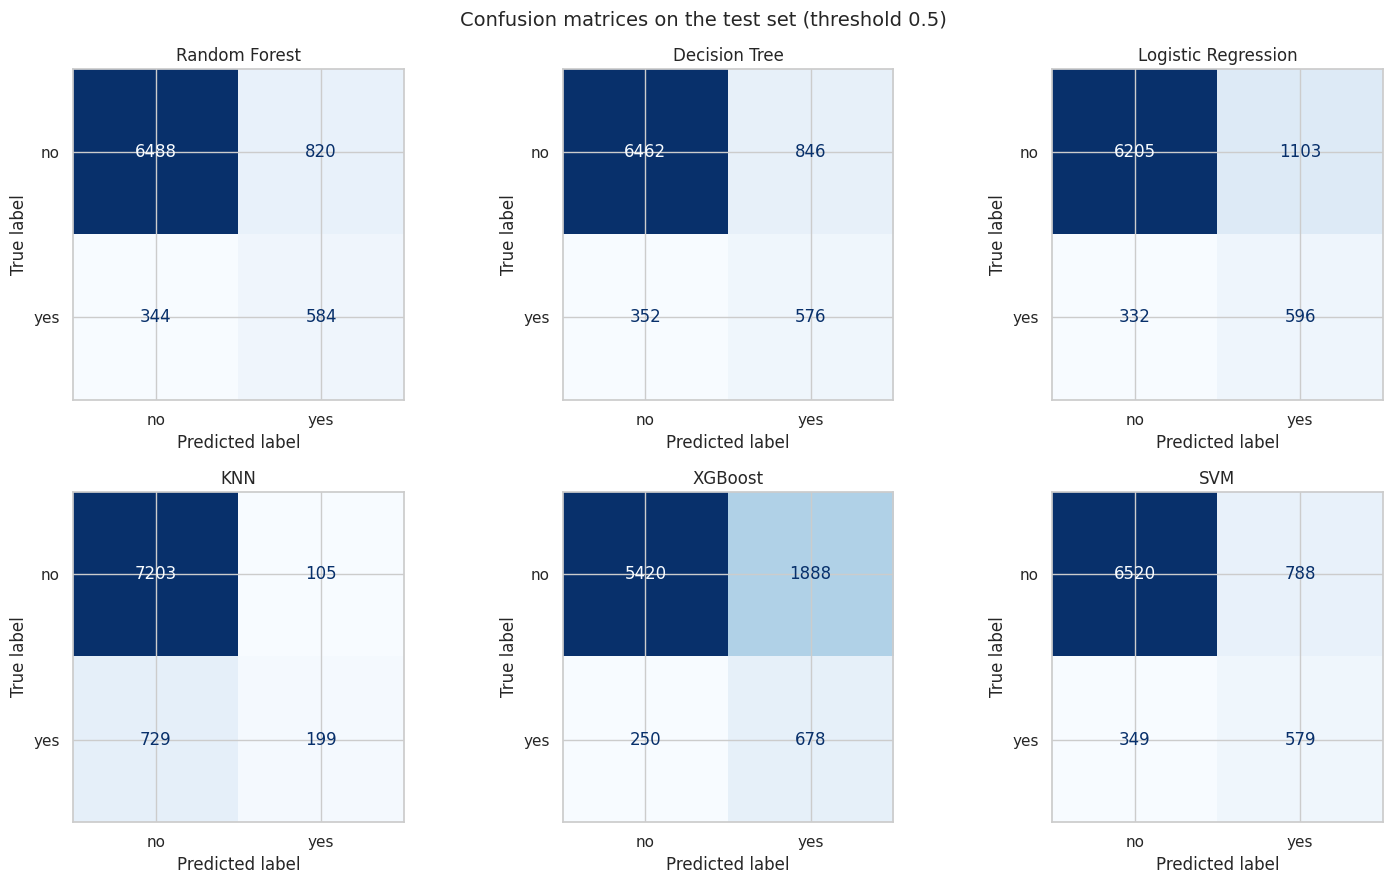

Figure 10. Top-left = true 'no', bottom-right = true 'yes' (found subscribers), bottom-left = missed subscribers, top-right = wasted calls.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.ravel(), results_df.index):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                 values_format="d")
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.suptitle("Confusion matrices on the test set (threshold 0.5)", fontsize=14)
plt.tight_layout()
plt.show()
print("Figure 10. Top-left = true 'no', bottom-right = true 'yes' (found subscribers), "
      "bottom-left = missed subscribers, top-right = wasted calls.")

### 4.2 ROC curves and Precision–Recall curves

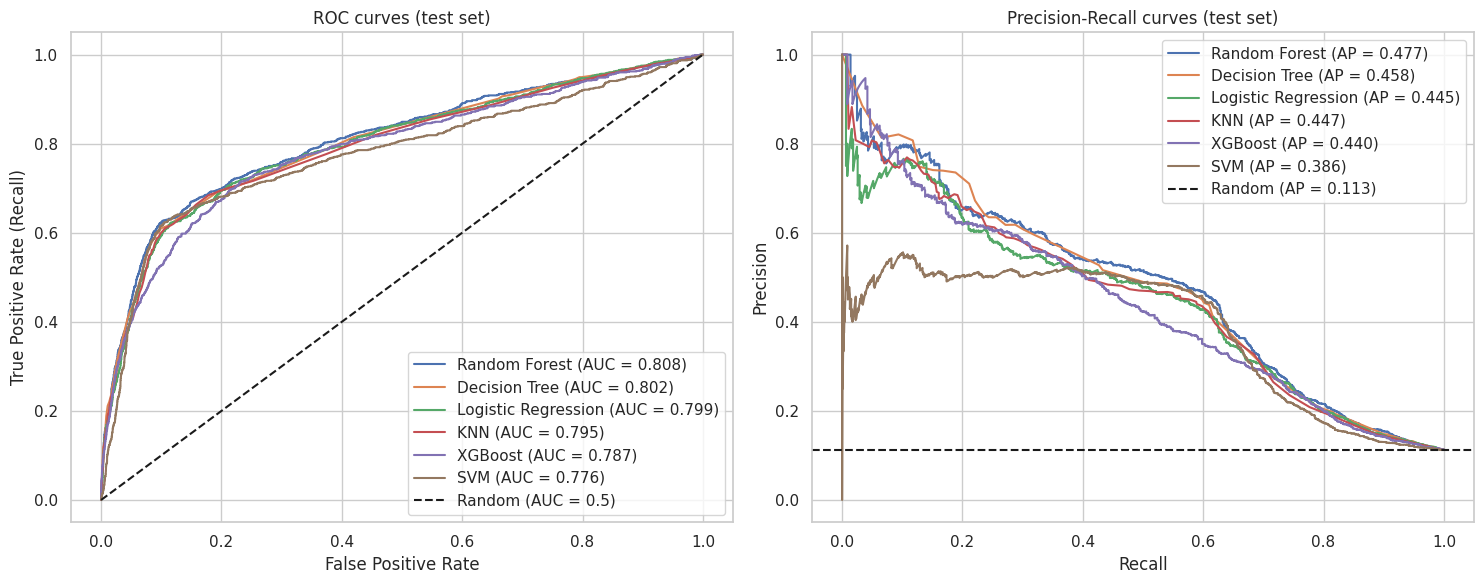

Figure 11. Left: ROC curves. Right: PR curves. Higher curve = better model. The PR curve shows the difference between models more clearly on imbalanced data.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name in results_df.index:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {results_df.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, scores[name])
    axes[1].plot(rec, prec, label=f"{name} (AP = {results_df.loc[name, 'PR-AUC']:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
axes[0].set_title("ROC curves (test set)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

base = y_test.mean()
axes[1].axhline(base, color="k", linestyle="--", label=f"Random (AP = {base:.3f})")
axes[1].set_title("Precision-Recall curves (test set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()
print("Figure 11. Left: ROC curves. Right: PR curves. Higher curve = better model. "
      "The PR curve shows the difference between models more clearly on imbalanced data.")

### 4.3 Interpretation of the evaluation
(Look at the results table, Figure 9 and Figure 11.)

- **All models are much better than random.** ROC-AUC is between 0.78 and 0.81, and PR-AUC is between 0.39 and 0.48, while the random PR-AUC is only 0.113.
- **The two ensembles (XGBoost and Random Forest) are the best** by both ROC-AUC (0.81) and PR-AUC (0.48). But the differences are small: the tuned Decision Tree (0.80) and Logistic Regression (0.80) are very close. This means a simple model already captures most of the signal.
- **PR-AUC is low for every model (below 0.5).** Predicting "yes" is hard without duration: many "no" clients look exactly like "yes" clients.
- **Precision vs Recall trade-off.** The models with class weights have Recall 0.62–0.64 but Precision only ≈0.35–0.42: they find about 2 of 3 subscribers, but more than half of the "yes" predictions are wrong (wasted calls). KNN has no class weights, so it is the opposite - Precision 0.65, but Recall only 0.21.
- **Accuracy is misleading:** KNN has the highest accuracy (0.90) but finds the fewest subscribers.
- **F1 at 0.5 depends on the threshold.** SVM has a good F1 at the default threshold, but its ROC-AUC and PR-AUC are the lowest, so its ranking of clients is the worst. SVM was also trained on only 10,000 rows.
- **The Decision Tree** is a bit weaker than Random Forest - averaging many trees reduces variance.

### 4.4 Threshold tuning for the best model
The default threshold 0.5 is not always the best. I choose a new threshold that **maximizes F1**. To avoid leakage, I find the threshold with **cross-validated predictions on the training set**, not on the test set.

In [ ]:
best_name = results_df["PR-AUC"].idxmax()
best_model = models[best_name]
print("Best model by PR-AUC:", best_name)

oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print("Best threshold (from train CV): %.3f" % best_thr)

s = scores[best_name]
rows = []
for t, label in [(0.5, "default 0.5"), (best_thr, f"tuned {best_thr:.2f}")]:
    p = (s >= t).astype(int)
    rows.append({"Threshold": label, "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
pd.DataFrame(rows).set_index("Threshold").round(4)

Best model by PR-AUC: Random Forest
Best threshold (from train CV): 0.643


,Precision,Recall,F1
Threshold,,,
default 0.5,0.4160,0.6293,0.5009
tuned 0.64,0.4741,0.5830,0.5230


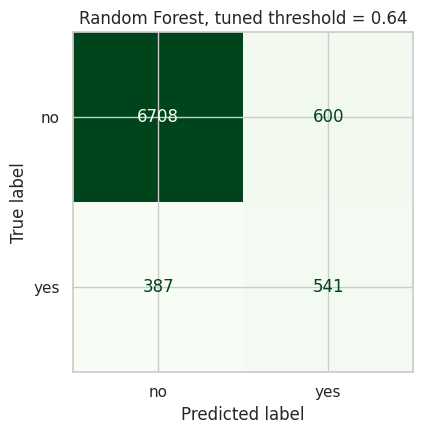

Figure 12. Confusion matrix of the best model after threshold tuning.


In [ ]:
p_t = (s >= best_thr).astype(int)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_t), display_labels=["no", "yes"]).plot(
    ax=ax, cmap="Greens", colorbar=False, values_format="d")
ax.set_title(f"{best_name}, tuned threshold = {best_thr:.2f}")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()
plt.show()
print("Figure 12. Confusion matrix of the best model after threshold tuning.")

**Interpretation.** The best threshold is higher than 0.5 (0.64). The model now predicts "yes" less often: Precision goes up (0.40 -> 0.47), Recall goes down a little (0.63 -> 0.60), and F1 goes up (0.49 -> 0.53). In practice, the bank can choose the threshold by business needs: if calls are cheap, use a low threshold (higher Recall); if calls are expensive, use a high threshold (higher Precision).

### 4.5 Feature importance

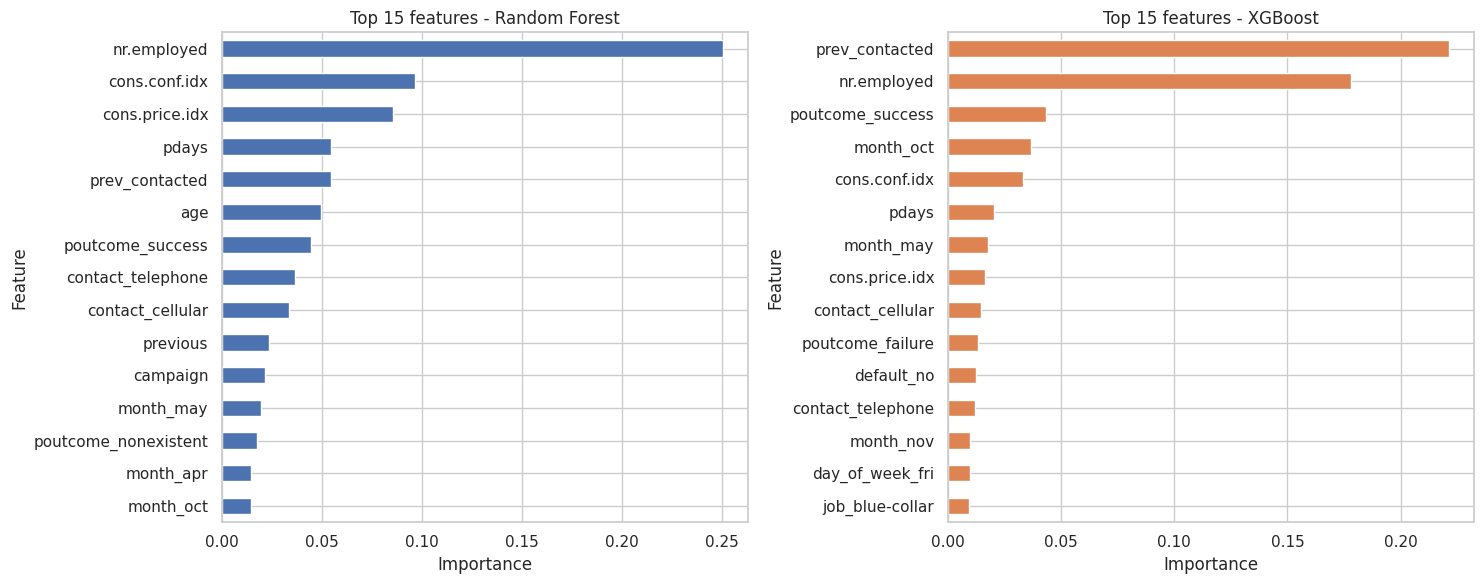

Figure 13. The most important features for the two tree ensembles.


In [ ]:
rf = models["Random Forest"].named_steps["clf"]
xgb = models["XGBoost"].named_steps["clf"]
names = models["Random Forest"].named_steps["prep"].get_feature_names_out()
names = [n.replace("num__", "").replace("cat__", "") for n in names]

imp = pd.DataFrame({"Random Forest": rf.feature_importances_,
                    "XGBoost": xgb.feature_importances_}, index=names)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, col, color in zip(axes, imp.columns, ["#4C72B0", "#DD8452"]):
    imp[col].sort_values().tail(15).plot(kind="barh", ax=ax, color=color)
    ax.set_title(f"Top 15 features - {col}")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()
print("Figure 13. The most important features for the two tree ensembles.")

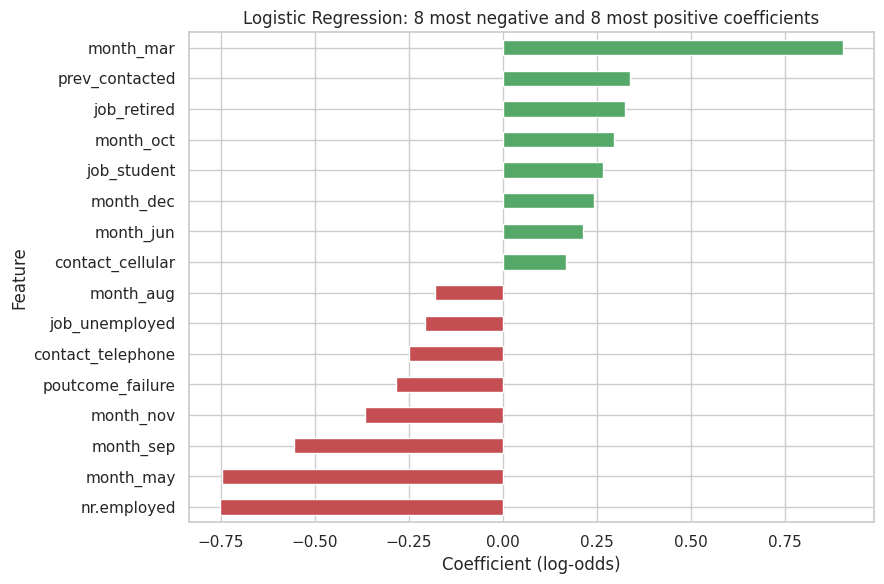

Figure 14. Green = increases the chance of 'yes', red = decreases it.


In [ ]:
# Logistic Regression coefficients (on scaled / one-hot features)
lr = models["Logistic Regression"].named_steps["clf"]
coef = pd.Series(lr.coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
pd.concat([coef.head(8), coef.tail(8)]).plot(kind="barh", ax=ax,
    color=["#C44E52"] * 8 + ["#55A868"] * 8)
ax.set_title("Logistic Regression: 8 most negative and 8 most positive coefficients")
ax.set_xlabel("Coefficient (log-odds)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()
print("Figure 14. Green = increases the chance of 'yes', red = decreases it.")

**Interpretation.**
- In the Random Forest the most important feature by far is nr.employed (0.27), then the other economic features (cons.conf.idx, cons.price.idx). After them come the previous campaign features (pdays, prev_contacted, poutcome_success), age and the contact type. XGBoost shows a similar picture (check Figure 13).
- Logistic Regression shows the direction of the effect: March, being contacted before (prev_contacted), retired and student clients and months like October and December increase the chance of "yes"; a high nr.employed, May, a failed previous campaign and telephone contact decrease it.
- Personal features (job, education, marital) are less important than when and how the client is called.

## 5. Discussion and summary of insights

### What I did
I used the **Bank Marketing** dataset (bank-additional-full.csv, 41,188 clients, 20 features). I did a full EDA, cleaned and prepared the data (duplicates, leakage, special values, "unknown" values, multicollinearity, outliers, encoding, scaling, class imbalance), trained **6 models** and compared them with **ROC-AUC, PR-AUC, F1, Precision, Recall, confusion matrices, ROC and PR curves**.

### Main results
1. **The data is imbalanced** (11.3% "yes"). Accuracy is not useful here; PR-AUC, Recall and F1 show the real quality. Without balancing, models find only about 20% of subscribers.
2. **Removing duration is important.** It is the strongest feature, but it is only known after the call, so using it would give unrealistic results.
3. **Best models:** XGBoost and Random Forest (ROC-AUC ≈0.81, PR-AUC ≈0.48). Logistic Regression and the Decision Tree are only a little worse (≈0.80) and are **much easier to explain**, so they are also a good choice for a bank.
4. **KNN and SVM are the weakest** by ROC-AUC and PR-AUC: KNN has no class weights (Recall 0.21 at 0.5), and SVM is slow, so I could train it only on a sample.
5. **Threshold tuning** improves F1 (from 0.49 to 0.53 for the best model) without retraining the model.

### Business insights (what the bank can learn)
- **The economic situation matters most.** People subscribe much more when interest rates and employment numbers are low.
- **Previous success = best lead.** Clients who said "yes" in a previous campaign say "yes" again about 65% of the time. They should be called first.
- **Use mobile phones.** Cellular contact works about 3× better than a home telephone.
- **Do not call too many times.** More calls in one campaign do not increase success.
- **Target students and retired clients**; the success rate for them is 2–3 times higher than average.
- **Timing:** May had the most calls but the lowest success. Months like March, September, October and December were much more successful.

### Limitations and future work
- Without duration, PR-AUC is still below 0.5 - many clients are hard to predict.
- The data is ordered by time (2008-2010, during a financial crisis). A time-based split would test the model more honestly for the future.
- Next steps: SMOTE, more hyperparameter tuning (e.g. RandomizedSearchCV for XGBoost), LightGBM/CatBoost, and model calibration.